# Fashion-MNIST Clothing Classification

## Imports

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    log_loss, accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import ConfusionMatrixDisplay

## a) Load Data
- Source: [(https://www.tensorflow.org/datasets/catalog/fashion_mnist)]

`fashion_mnist` is a dataset of clothing article images, with a training set of 60,000 images and a testing set of 10,000 images. Each examples is 28x28 pixel grayscale image, associated with a label from one of 10 classes. `fashion_mnist` can be loaded from `tensorflow.keras.datasets`. The dataset is tuple consisting of `(train, test)`, each of these being a tuple `(x, y)`. `x` and `y` are 2D arrays. Scikit-Learn's `train_test_split` funciton is used to take a subset of the data.

In [3]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Select subset of 12,000 samples
X_subset, _, y_subset, _ = train_test_split(
    X_train, y_train,
    train_size=12_000,
    stratify=y_train,
    random_state=42)

### Training testing split

Next we split the 12,000-image subset into training and validation subsets. We will continue to use the original 10,000 testing examples as our testing dataset. `stratify=y_subset` keeps the class proportions similar in the training and validation sets.

In [5]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_subset,
    y_subset,
    test_size=0.20,
    stratify=y_subset,
    random_state=42,)

splits = {
    "Training": (X_train_sub, y_train_sub),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)}

### Flatten images

Regression expects 2-dimensional data. However, our original dataset is 3-dimensional, since each individual example is a 2D image. In order to make the data 2-dimensional, each image will need to be flattened into a one-dimensional feature vector. `reshape(-1,)` reshapes an array into one dimension. Numpy infers the length from the number of elements. Since $28 \times 28 = 784$, we expect a 784-length vector.

In [6]:
for name, array in [("X_train_sub", X_train_sub), ("X_val", X_val), ("X_test", X_test)]:
    print(f"{name} before: {array.shape}")

X_train_sub = X_train_sub.reshape(-1, 784)
X_val = X_val.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

for name, array in [("X_train_sub", X_train_sub), ("X_val", X_val), ("X_test", X_test)]:
    print(f"{name} after:  {array.shape}")

X_train_sub before: (9600, 28, 28)
X_val before: (2400, 28, 28)
X_test before: (10000, 28, 28)
X_train_sub after:  (9600, 784)
X_val after:  (2400, 784)
X_test after:  (10000, 784)


### Report shape and class counts
- Source: [(https://www.geeksforgeeks.org/pandas/python-pandas-series/)]

A pandas Series is a 1D array, similar to a column for a DataBase. A Series has values and an index (label). This means we can use `.iloc[n]` for the item at position `n`, or `.loc[label]` for the item with that index label. For the Fashion-MNIST dataset, labels `0-9` identify the clothing classes. The `value_counts()` method counts how many times each class label appears. We construct the 1D Series `counts`, where each index is a class label, and its value is that class's sample count. A table of each dataset's information is constructed.

In [9]:
rows = []
for name, (X, y) in splits.items():
    counts = pd.Series(y).value_counts()
    rows.append({
        "Split": name,
        "X shape": X.shape,
        "y shape": y.shape,
        **{f"Class {c}": counts[c] for c in range(10)},
    })

display(pd.DataFrame(rows).set_index("Split"))

,X shape,y shape,Class 0,Class 1,Class 2,Class 3,Class 4,Class 5,Class 6,Class 7,Class 8,Class 9
Split,,,,,,,,,,,,
Training,"(9600, 28, 28)","(9600,)",960,960,960,960,960,960,960,960,960,960
Validation,"(2400, 28, 28)","(2400,)",240,240,240,240,240,240,240,240,240,240
Test,"(10000, 28, 28)","(10000,)",1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


### Display one labeled image from each class
- Source: [(https://www.geeksforgeeks.org/python/matplotlib-pyplot-subplots-in-python/)]
- source: [(https://medium.com/@ebimsv/mastering-matplotlib-part-5-working-with-images-3041fcdd88ff)]
- Source: [(https://www.geeksforgeeks.org/numpy/numpy-sorting-searching-and-counting/)]

Matplotlib's `.subplots(n_rows, n_cols, figsize)` method allows us to create multiple plots in a single figure. The function returns `fig` and `axes`. `fig` is the overall figure, and `axes` is the `n_rows`x`n_cols` array of individual plot areas. `axes` is a Numpy array of Matplotlib `Axes` objects. A Matplotlib `Axes` object represents a single subplot, and is used to draw and customize that plot.

`axes.flat` turns the 2D array of subplots `Axes` objects into a single sequence of objects, allowing us to loop over all 10 plots. `label` is an integer, which we can map to a Fashion-MNIST class. 

`np.flatnonzero` returns the inidices of all nonzero (`True`) elements in an array. We find the positions where `y_train_sub == label`, then choose the first position. This gives us the index for an image of the class we desire.

Matplotlib's `imshow` displays an image from a variety of inputs including 2D arrays for grayscale images and 2D arrays for RGB images. In order to display the image, we need to reshape the flattened image back into a 2D 28x28 array. `tight_layout()` adjusts spacing fo that subplot titles and labels don't overlap.

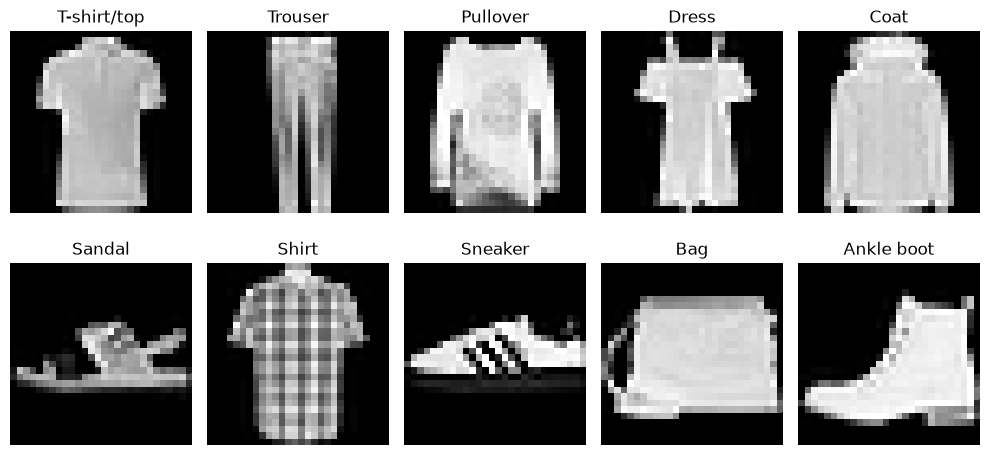

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for label, ax in enumerate(axes.flat):
    i = np.flatnonzero(y_train_sub == label)[0]
    ax.imshow(X_train_sub[i].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## b) Multinomial logistic regression
- Source: [(https://www.datacamp.com/tutorial/understanding-logistic-regression-python)]
- Source: [(https://www.geeksforgeeks.org/machine-learning/sklearn-classification-metrics/)]

Logistic regression is a common way of solving classification problems. Multinomial classification handles the case where multiple classes are present in the target variable. Logistic regression is a method for predicting binary classes. It is used to test the relationship between one binary dependent variable and one or many independent varaibles. 

Logistic regression is obtained by applying the Sigmoid function to Linear Regression:

Multinomial Linear Regression: $y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n$

Sigmoid Function: $p = \frac{1}{1 + e^{-y}}$

Logistic Regression: $p = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n)}}$

Properties of Logistic Regression:
- Dependent variable follows Bernoulli Distribution
- Estimation is done through maximum liklihood (MLE) rather than ordinary least squares (OSL)
- No `R^2` score, fitness is calculated through Concordance, KS-Statistics.

When we instantiate the model, we select the L-BFGS optimization algorithm. We choose the L2 penalty, which adds a cost for large model coefficients (L2 penalty is implied by use of `C` parameter). This encourages smaller weights, which helps reduce overfitting. `C` is the model's regularization setting. A smaller `C` makes the model coefficients smaller, while a larger 'C' makes the model coefficients larger. We set a maximum number of optimization steps `max_iter=3000`.

In [16]:
models = {}
results = []

for C in (0.01, 0.1, 1.0):
    model = LogisticRegression(
        solver="lbfgs",
        C=C,
        max_iter=3000,
        random_state=42)

    model.fit(X_train_sub, y_train_sub)

    models[C] = model
    results.append({
        "C": C,
        "Validation accuracy": accuracy_score(y_val, model.predict(X_val))})

results = pd.DataFrame(results)
display(results)

c:\Users\codett\anaconda3\envs\Energy-Disaggregation\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\codett\anaconda3\envs\Energy-Disaggregation\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://sciki

,C,Validation accuracy
0,0.01,0.771667
1,0.10,0.764167
2,1.00,0.764167


For each of the `C` values, we get a warning that the solve reached the maximum number of iteration before convergence occured. This indicates that increasing the maximum allowable iterations would improve performance, but would also increase the solve time. We also see that the validation accurcy is similar for each `C` value, but is slightly higher for `C=0.01`, the lowest `C` value.

#### Choose model with highest validation accuracy

`results["Validation accuracy"].idxmax()` finds the row index with the highest validation accuracy. After getting the `best_C` and `best_model`, we test the best model. `predict(x_test)` predicts a clothing class for each test image. `predict_proba(x_test)` returns the probabilities for each class. We find the error metrics for the best model. 

Test accuracy is the fraction of predictions that are correct. F1-score balances precision and recall, with a value of 1.0 being the best. Macro-F1 calculates F1 for each class, then averages them equally, so each clothing category matters equally. Log loss evaluates the predicted probabilities, penalizing confident incorrect predictions more heavily. Passing `labels=best_model.classes_` ensures the probability columns are matched to the right class labels.

In [17]:
best_C = results.loc[results["Validation accuracy"].idxmax(), "C"]
best_model = models[best_C]

test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)

print(f"Selected model: C={best_C}")

print(f"Test accuracy: {accuracy_score(y_test, test_pred):.4f}")
print(f"Test macro-F1: {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"Test log loss: {log_loss(y_test, test_prob, labels=best_model.classes_):.4f}")

Selected model: L2, C=0.01
Test accuracy: 0.7558
Test macro-F1: 0.7562
Test log loss: 3.3213


The model with `C = 0.01` performed the best on validation data, so it was selected. Its test accuracy and test F1-score are both 0.756, showing balanced performance across all ten classes. However, the log loss of 3.32 is relatively high, showing the model makes some confident mistakes, even though its predictions are correct most of the time.

## Confusion matrix
- Source: [(https://www.geeksforgeeks.org/machine-learning/confusion-matrix-machine-learning/)]
- Source: [(https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html)]

The Confusion Matrix is used to measure the performance of a classification model, breaking predictions into four categories:
- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

The `ConfusionMatrixDisplay` class can be imported from Scikit-Learn. The `.from_predictions` method compares true labels with predicted labels, calculates the confusion matrix, and plots it. The `disp` return is the `ConfusionMatrixDisplay` object. The `.confusion_matrix` attribute contains the actual matrix. `cm` is a 2D NumPy array of shape `(num_classes, num_classes)`. Rows are true classes, columns are predicted values, and each cell counts a prediction.

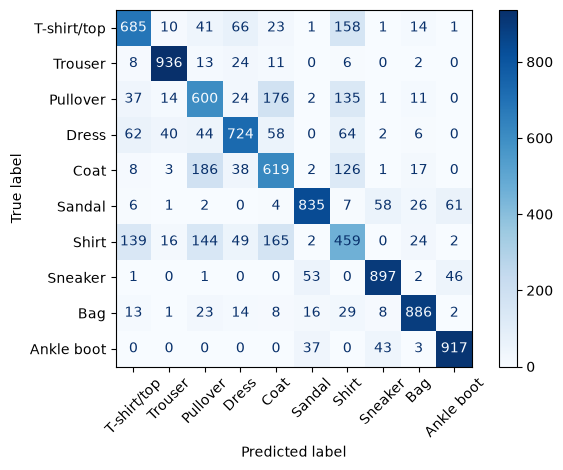

In [20]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues")
plt.tight_layout()
plt.show()

cm = disp.confusion_matrix

The model frequently confuses  `Pullover` and `Coat`, with 176 pullovers misclassified as coats and 186 coats misclassified as pullovers. Another frequent confusion is `Shirt` and `T-shirt/top`, with 139 shirts misclassified as `T-shirts/tops` and 158 `T-shirts/tops` misclassified as shirts. This makes sense, as these classes are similar clothing types and have similar shapes.

#### Accuracy, Precision, and Recall

Accuracy shows the fraction of the predictions the model got right. It gives a measure of overall performance, but can be misleading when one class makes up a higher share of the examples.

$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$

Precision shows how many of the positive predictions were correct. It is helpful for situations where false positives should be minimized.

$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$

Recall measures what proportion of true positives were detected.

$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$

F1-Score combines precision and recall into a single metric, providing a better sense of a model's overall performance on an unbalanced dataset.

$\text{F1-Score} = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$

In [26]:
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp
tn = cm.sum() - tp - fp - fn

accuracy_per_class = (tp + tn) / cm.sum()
precision_per_class = np.divide(tp, tp + fp)
recall_per_class = np.divide(tp, tp + fn)
f1_per_class = np.divide(
    2 * precision_per_class * recall_per_class,
    precision_per_class + recall_per_class)

metrics_table = pd.DataFrame(
    {
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Accuracy": accuracy_per_class,
        "Precision": precision_per_class,
        "Recall": recall_per_class,
        "F1-score": f1_per_class,
    }, index=class_names)

# Compute overall model metrics from the summed TP/TN/FP/FN values across classes
tp_total = tp.sum()
tn_total = tn.sum()
fp_total = fp.sum()
fn_total = fn.sum()

accuracy_total = (tp_total + tn_total) / (tp_total + tn_total + fp_total + fn_total)
precision_total = tp_total / (tp_total + fp_total)
recall_total = tp_total / (tp_total + fn_total)
f1_total = (2 * precision_total * recall_total) / (precision_total + recall_total)

metrics_table.loc["Overall (model)"] = {
    "TP": tp_total,
    "TN": tn_total,
    "FP": fp_total,
    "FN": fn_total,
    "Accuracy": accuracy_total,
    "Precision": precision_total,
    "Recall": recall_total,
    "F1-score": f1_total}

display(metrics_table.round(4))

,TP,TN,FP,FN,Accuracy,Precision,Recall,F1-score
T-shirt/top,685,8726,274,315,0.9411,0.7143,0.6850,0.6993
Trouser,936,8915,85,64,0.9851,0.9167,0.9360,0.9263
Pullover,600,8546,454,400,0.9146,0.5693,0.6000,0.5842
Dress,724,8785,215,276,0.9509,0.7710,0.7240,0.7468
Coat,619,8555,445,381,0.9174,0.5818,0.6190,0.5998
Sandal,835,8887,113,165,0.9722,0.8808,0.8350,0.8573
Shirt,459,8475,525,541,0.8934,0.4665,0.4590,0.4627
Sneaker,897,8886,114,103,0.9783,0.8872,0.8970,0.8921
Bag,886,8895,105,114,0.9781,0.8940,0.8860,0.8900
Ankle boot,917,8888,112,83,0.9805,0.8912,0.9170,0.9039


## d) Classify T-Shirt/Top and Shirts


The `filter_binary()` function keeps only classes `0` and `6`, then converts their labels into binary values `0` and `1`. The `mask` finds samples whose labels are `0` or `6`, and `x_filtered` keeps only those samples. Then the `6` label is converted to `1`.

In [27]:
def filter_binary(X, y):
    mask = np.isin(y, [0, 6])
    X_filtered = X[mask]
    y_binary = (y[mask] == 6).astype(int)  # T-shirt/top=0, shirt=1
    return X_filtered, y_binary

This function is called on the training, validation, and testing datasets.

In [28]:
X_train_bin, y_train_bin = filter_binary(X_train_sub, y_train_sub)
X_val_bin, y_val_bin = filter_binary(X_val, y_val)  # Filtered, not used for fitting
X_test_bin, y_test_bin = filter_binary(X_test, y_test)

We fit the binary data into a logistic regression with the same parameters as part b). The `predict_proba` method returns each test image's sigmoid score (between 0 and 1) for both classes. We then predict shirt (`1`) when the sigmoid is at least 0.5, otherwise we predict not a shirt (`0`). 

In [29]:
model_bin = LogisticRegression(solver="lbfgs", C=0.01, penalty="l2", max_iter=3000, random_state=42)
model_bin.fit(X_train_bin, y_train_bin)

# Predict shirt (class 1) when its sigmoid probability is at least 0.5
shirt_prob = model_bin.predict_proba(X_test_bin)[:, 1]
y_pred_bin = (shirt_prob >= 0.5).astype(int)

c:\Users\codett\anaconda3\envs\Energy-Disaggregation\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Next, we find the confusion matrix and metrics again, using the same method as part c).

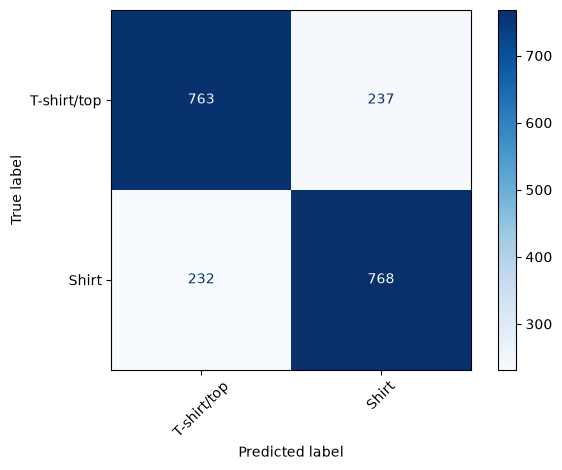

Binary confusion matrix:
[[763 237]
 [232 768]]
Accuracy: 0.7655
Precision (Shirt): 0.7642
Recall (Shirt): 0.7680
F1-score (Shirt): 0.7661


In [30]:
class_names_bin = ["T-shirt/top", "Shirt"]

disp = ConfusionMatrixDisplay.from_predictions(
    y_test_bin,
    y_pred_bin,
    display_labels=class_names_bin,
    cmap="Blues",
    xticks_rotation=45)
plt.tight_layout()
plt.show()

cm_bin = disp.confusion_matrix

print(f"Binary confusion matrix:\n{cm_bin}")
print(f"Accuracy: {accuracy_score(y_test_bin, y_pred_bin):.4f}")
print(f"Precision (Shirt): {precision_score(y_test_bin, y_pred_bin, pos_label=1):.4f}")
print(f"Recall (Shirt): {recall_score(y_test_bin, y_pred_bin, pos_label=1):.4f}")
print(f"F1-score (Shirt): {f1_score(y_test_bin, y_pred_bin, pos_label=1):.4f}")

For the 10-class model, the precision, recall and F1 were 0.4665, 0.4590, and 0.4627. In comparison, the binary model, which only distinguishes Shirts from T-shirts/tops, reported precision, recall and F1 of 0.7642, 0.7680, and 0.7661. This is a significant improvement. The confusion matrix also shows improved results.

The binary classifier uses a sigmoid output, where the ten-class classifier uses a softmax output. The sigmoid output gives a probability for a single class, where the softmax gives probabilities for all ten classes that sum to 1, and then predicts the class with the highest probability.

## e) Misclassified images

We use Numpy's `flatnonzero` to find the indices where predictions differ from true labels, then keep the first five misclassified examples. Like in part a), we display each image as a Matplotlib subplot. 

For each image, we use NumPy's `argsort` to sort indices by probability. We select the top two, then reverse them. We use these indices to get the label and probability of the two classes with the highest predicted probabilities. Along with each image, we display the true class, the predicted class, and the classes with the top two predicted probabilities.

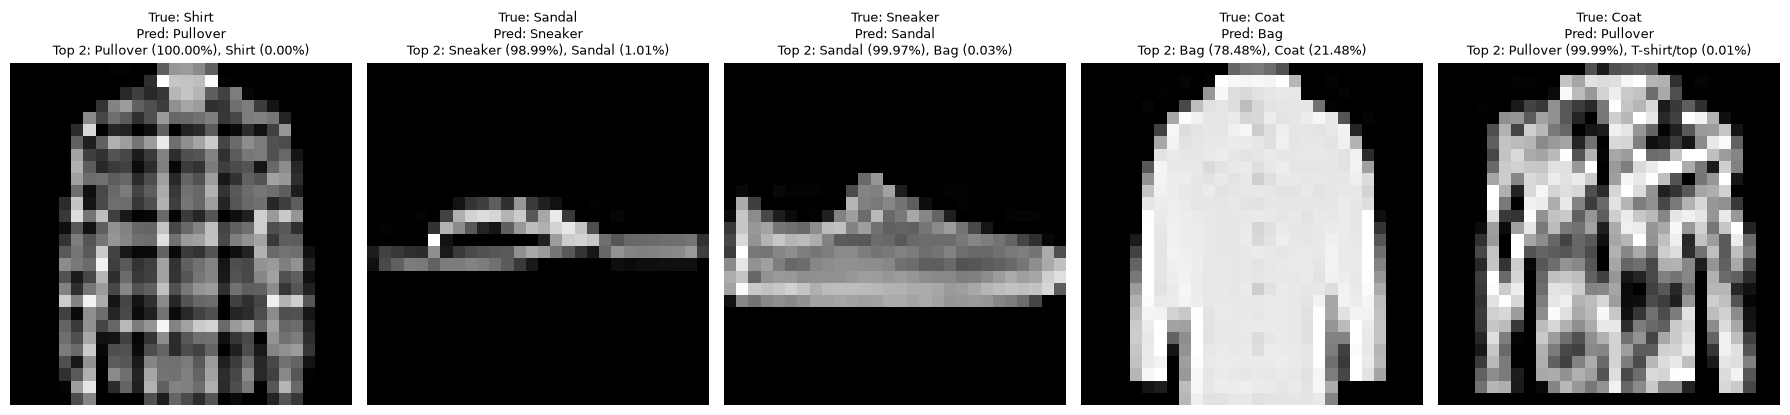

In [31]:
mis_idx = np.flatnonzero(y_test != test_pred)[:5]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, idx in zip(axes, mis_idx):
    true_label = int(y_test[idx])
    pred_label = int(test_pred[idx])

    top2_idx = np.argsort(test_prob[idx])[-2:][::-1] # Select the top two, then reverse.
    top2_labels = [class_names[j] for j in top2_idx]
    top2_probs = [test_prob[idx, j] for j in top2_idx]

    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Top 2: {top2_labels[0]} ({top2_probs[0]:.2%}), {top2_labels[1]} ({top2_probs[1]:.2%})",
        fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

For the first example (Shirt), the model misclassified the image with 100-percent confidence in its incorrect prediction. The second misclassification (Sandal), showed a similarly high false-confidence. 